# Binary – Titanic (Survived)

**Sumber dataset:** seaborn-data (https://github.com/mwaskom/seaborn-data), data asli penumpang kapal Titanic

Data tabular campuran numerik & kategorikal. Tugas: memprediksi penumpang **selamat (1)** atau **tidak (0)**.

**Klasifikasi biner** = data dikelompokkan ke tepat **dua** kategori (ya/tidak).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def ringkas(df, fitur, target, modalitas):
    """Cetak identifikasi fitur/target, jumlah data & variabel, dan jenis klasifikasi."""
    print("Jumlah data (baris)      :", df.shape[0])
    print("Jumlah variabel (kolom)  :", df.shape[1])
    print("Jumlah fitur             :", len(fitur))
    print("Jumlah kolom target      :", len(target))
    print("Modalitas data           :", modalitas)
    print("Contoh fitur             :", [str(x) for x in fitur[:6]], "..." if len(fitur) > 6 else "")
    print("Target (label)           :", [str(x) for x in target[:6]], "..." if len(target) > 6 else "")
    if len(target) == 1:
        k = df[target[0]].nunique()
        jenis = "Klasifikasi Biner" if k == 2 else "Klasifikasi Multikelas"
        print(f"Jumlah kelas             : {k}")
        print("Distribusi kelas         :\n", df[target[0]].value_counts().to_string())
    else:
        per_baris = df[target].sum(axis=1)
        print("Rata-rata label/sampel   :", round(per_baris.mean(), 2), "| maks:", per_baris.max())
        jenis = "Klasifikasi Multilabel"
    print("\n>>> KESIMPULAN:", jenis)
    return jenis

## 1. Muat dataset & ubah ke DataFrame

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Identifikasi fitur, target, jumlah data & variabel

In [3]:
target = ['survived']
# 'alive' adalah salinan teks dari 'survived' (kebocoran label) -> bukan fitur
fitur = [c for c in df.columns if c not in ('survived', 'alive')]
ringkas(df, fitur, target, "Tabular (numerik + kategorikal)")

Jumlah data (baris)      : 891
Jumlah variabel (kolom)  : 15
Jumlah fitur             : 13
Jumlah kolom target      : 1
Modalitas data           : Tabular (numerik + kategorikal)
Contoh fitur             : ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare'] ...
Target (label)           : ['survived'] 
Jumlah kelas             : 2
Distribusi kelas         :
 survived
0    549
1    342

>>> KESIMPULAN: Klasifikasi Biner


'Klasifikasi Biner'

## 3. Eksplorasi data

In [4]:
print("Tipe data tiap kolom:")
df.info()

print("\nJumlah nilai kosong per kolom:")
kosong = df.isna().sum()
print(kosong[kosong > 0].to_string())

print("\nJenis fitur:")
fitur_num = df[fitur].select_dtypes(include='number').columns.tolist()
fitur_kat = [c for c in fitur if c not in fitur_num]
print("  Numerik   :", fitur_num)
print("  Kategorikal:", fitur_kat)

print("\nStatistik deskriptif fitur numerik:")
df[fitur_num].describe().round(2)

Tipe data tiap kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Jumlah nilai kosong per kolom:
age            177
embarked         2
deck           68

,pclass,age,sibsp,parch,fare
count,891.00,714.00,891.00,891.00,891.00
mean,2.31,29.70,0.52,0.38,32.20
std,0.84,14.53,1.10,0.81,49.69
min,1.00,0.42,0.00,0.00,0.00
25%,2.00,20.12,0.00,0.00,7.91
50%,3.00,28.00,0.00,0.00,14.45
75%,3.00,38.00,1.00,0.00,31.00
max,3.00,80.00,8.00,6.00,512.33


## 4. Visualisasi

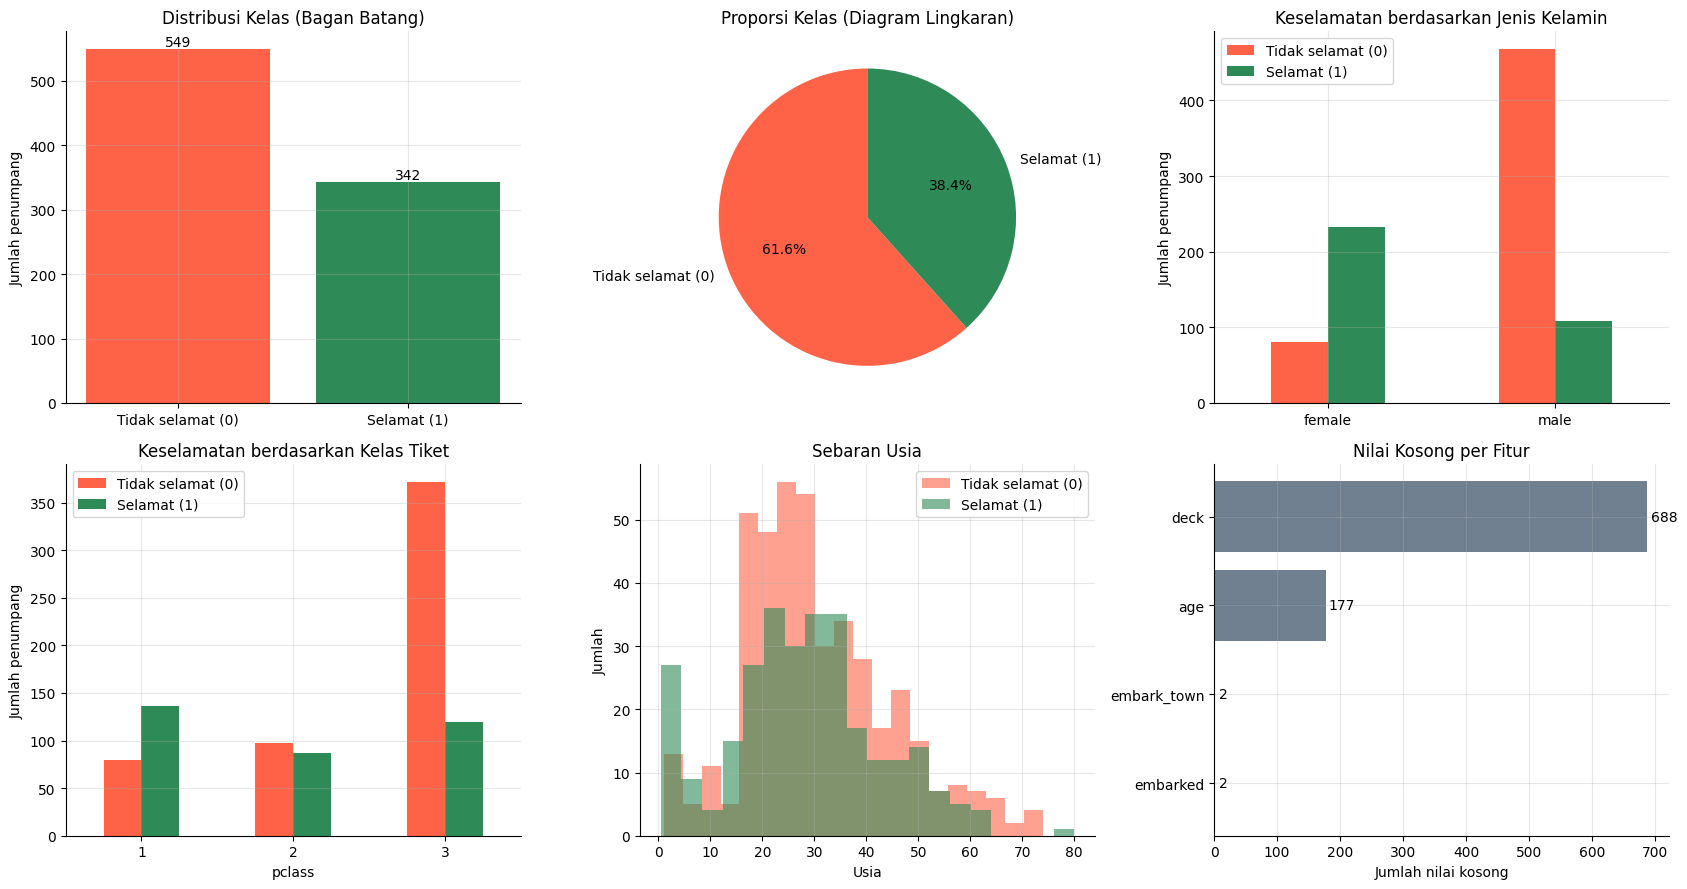

Rasio kelas mayoritas : minoritas = 1.61 : 1 (61.6% vs 38.4%) -> relatif cukup seimbang, tetapi tetap perlu diperhatikan saat evaluasi model.


In [5]:
warna = ['tomato', 'seagreen']
label = ['Tidak selamat (0)', 'Selamat (1)']
cnt = df['survived'].value_counts().sort_index()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# (1) Bagan batang distribusi kelas
ax = axes[0, 0]
ax.bar(label, cnt.values, color=warna)
for i, v in enumerate(cnt.values):
    ax.text(i, v + 5, str(v), ha='center')
ax.set_title('Distribusi Kelas (Bagan Batang)')
ax.set_ylabel('Jumlah penumpang')

# (2) Diagram lingkaran distribusi kelas
ax = axes[0, 1]
ax.pie(cnt.values, labels=label, autopct='%1.1f%%', colors=warna, startangle=90)
ax.set_title('Proporsi Kelas (Diagram Lingkaran)')

# (3) Selamat vs jenis kelamin
ax = axes[0, 2]
pd.crosstab(df['sex'], df['survived']).plot(kind='bar', ax=ax, color=warna, rot=0)
ax.set_title('Keselamatan berdasarkan Jenis Kelamin')
ax.set_xlabel(''); ax.set_ylabel('Jumlah penumpang'); ax.legend(label)

# (4) Selamat vs kelas tiket
ax = axes[1, 0]
pd.crosstab(df['pclass'], df['survived']).plot(kind='bar', ax=ax, color=warna, rot=0)
ax.set_title('Keselamatan berdasarkan Kelas Tiket')
ax.set_xlabel('pclass'); ax.set_ylabel('Jumlah penumpang'); ax.legend(label)

# (5) Histogram usia per kelas target
ax = axes[1, 1]
for k in (0, 1):
    ax.hist(df.loc[df['survived'] == k, 'age'].dropna(), bins=20, alpha=0.6,
            color=warna[k], label=label[k])
ax.set_title('Sebaran Usia'); ax.set_xlabel('Usia'); ax.set_ylabel('Jumlah'); ax.legend()

# (6) Nilai kosong per fitur
ax = axes[1, 2]
mv = df[fitur].isna().sum()
mv = mv[mv > 0].sort_values()
if len(mv):
    ax.barh(mv.index, mv.values, color='slategray')
    for i, v in enumerate(mv.values):
        ax.text(v + 5, i, str(v), va='center')
ax.set_title('Nilai Kosong per Fitur'); ax.set_xlabel('Jumlah nilai kosong')

plt.tight_layout()
plt.show()

# Catatan ketidakseimbangan kelas
rasio = cnt.max() / cnt.min()
print(f"Rasio kelas mayoritas : minoritas = {rasio:.2f} : 1 "
      f"({cnt.max() / cnt.sum():.1%} vs {cnt.min() / cnt.sum():.1%}) -> relatif cukup seimbang, "
      "tetapi tetap perlu diperhatikan saat evaluasi model.")

## 5. Kesimpulan

- **Fitur (X):** pclass, sex, age, sibsp, parch, fare, embarked, dst. (`alive` dibuang karena duplikat target)
- **Target (y):** `survived` (0/1)
- **Jenis data:** tabular
- **Jenis klasifikasi: Biner** — hanya ada dua kelas (tidak selamat = 549, selamat = 342), dan setiap penumpang masuk ke tepat satu kelas.